# Практическое занятие №11–12. Метод главных компонент (PCA)

In [1]:
# Окружение и версии. Фиксируем сиды (random_state=17/42 — воспроизводимость),
# гасим UserWarning, печатаем версии (API StandardScaler/PCA/LogisticRegression — sklearn 1.9).
import warnings
warnings.filterwarnings('ignore')  # чистый вывод без UserWarning библиотек
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler  # стандартизация: z = (x - mean) / std
from sklearn.decomposition import PCA  # PCA через SVD: X = U S V^T, компоненты — строки V^T
from sklearn.linear_model import LogisticRegression  # логистическая регрессия на компонентах и исходных признаках
from sklearn.model_selection import train_test_split  # сплит 75/25, random_state=17
print('numpy', np.__version__)
print('pandas', pd.__version__)
print('matplotlib', matplotlib.__version__)
import sklearn
print('sklearn', sklearn.__version__)
np.random.seed(42)  # детерминизм демонстрационных данных

numpy 2.4.6
pandas 3.1.0
matplotlib 3.11.2
sklearn 1.9.1


## 0. Вводный пример: 2D-гауссиана и главные компоненты

Генерируем вытянутое облако точек, ищем ортогональные направления максимального разброса.

среднее: [0.02693656 0.00560258]
компоненты (строки — направления):
 [[ 0.83417993  0.55149237]
 [-0.55149237  0.83417993]]
объяснённая дисперсия: [5.37045673 0.3737106 ]
доли дисперсии: [0.93494086 0.06505914]


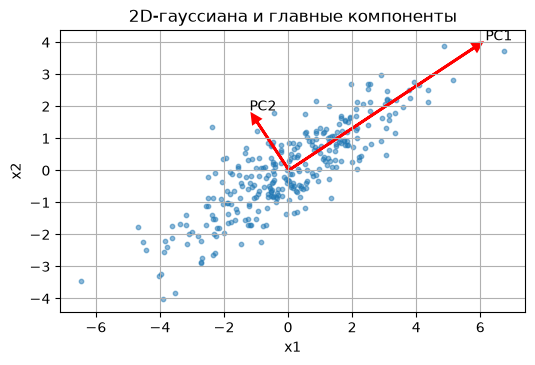

In [2]:
# Вводный пример PCA. Генерируем 2D-гауссиану: ковариация [[4, 2.4], [2.4, 2]] — облако
# вытянуто вдоль диагонали. PCA ищет собственные векторы ковариационной матрицы:
# первая компонента — направление максимальной дисперсии, вторая ортогональна ей.
# Стрелки: начало в среднем, направление — components_, длина ~ sqrt(explained_variance_).
rng = np.random.RandomState(42)  # фиксированный сид — картинка воспроизводима
cov = np.array([[4.0, 2.4], [2.4, 2.0]])  # вытянутая ковариация — облако вдоль диагонали
X_demo = rng.multivariate_normal(mean=[0, 0], cov=cov, size=300)  # 300 точек 2D-гауссианы
pca_demo = PCA(n_components=2).fit(X_demo)  # полный PCA: 2 компоненты из 2 признаков
print('среднее:', pca_demo.mean_)  # центр облака — начало стрелок
print('компоненты (строки — направления):\n', pca_demo.components_)  # собственные векторы
print('объяснённая дисперсия:', pca_demo.explained_variance_)  # собственные значения
print('доли дисперсии:', pca_demo.explained_variance_ratio_)  # нормированные доли
fig, ax = plt.subplots(figsize=(6, 5))  # холст под диаграмму рассеяния
ax.scatter(X_demo[:, 0], X_demo[:, 1], s=10, alpha=0.5)  # само облако точек
for i, (vec, val) in enumerate(zip(pca_demo.components_, pca_demo.explained_variance_)):  # по каждой компоненте
    ax.arrow(pca_demo.mean_[0], pca_demo.mean_[1],  # стрелка из центра облака
             vec[0] * 3 * np.sqrt(val), vec[1] * 3 * np.sqrt(val),  # длина ~ 3 сигмы вдоль направления
             head_width=0.25, head_length=0.25, fc='r', ec='r', lw=2)  # красные стрелки
    ax.text(pca_demo.mean_[0] + vec[0] * (3 * np.sqrt(val) + 0.4),  # подпись PC1/PC2 у конца стрелки
            pca_demo.mean_[1] + vec[1] * (3 * np.sqrt(val) + 0.4), f'PC{i+1}')
ax.set_title('2D-гауссиана и главные компоненты')  # заголовок по-русски
ax.set_xlabel('x1')  # подпись оси
ax.set_ylabel('x2')  # подпись оси
ax.set_aspect('equal')  # равный масштаб — направления не искажены
ax.grid(True)  # сетка для читаемости
plt.savefig('pca_demo.png', dpi=150)  # PNG рядом с ноутбуком
plt.show()

## Файл data_pca_200x16.csv — 200×16 (15 признаков)

Пункты 1–5 задания: загрузка и проверка, полный PCA и кривая дисперсии, правило 90%, извлечение компонент, логистическая регрессия на компонентах против исходных признаков.

### 1. Загрузка и проверка данных

In [3]:
# П.1: загрузка CSV. Формат европейский: разделитель ';', десятичная запятая —
# поэтому sep=';' и decimal=','. Последний столбец 'y' — непрерывная мишень.
df = pd.read_csv('data_pca_200x16.csv', sep=';', decimal=',')  # читаем европейский CSV
print('форма:', df.shape)  # строки × столбцы
print('столбцы:', list(df.columns[:3]), '...', list(df.columns[-3:]))  # первые/последние имена
print('пропуски по столбцам (ненулевые):')  # isnull().sum() — проверка качества данных
print(df.isnull().sum()[df.isnull().sum() > 0])  # пусто — пропусков нет
print('всего пропусков:', int(df.isnull().sum().sum()))  # контрольное число: 0
print(df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])  # описательные статистики
X = df.drop(columns=['y']).values  # матрица признаков (без мишени)
y = df['y'].values  # непрерывная мишень
print('X:', X.shape, 'y:', y.shape)  # размерности для PCA и ML

форма: (200, 16)
столбцы: ['x1', 'x2', 'x3'] ... ['x14', 'x15', 'y']
пропуски по столбцам (ненулевые):
Series([], dtype: int64)
всего пропусков: 0
     count     mean       std    min    50%    max
x1   200.0  6.19345  4.769595  -5.37  6.265  18.62
x2   200.0  0.18870  1.732768  -3.77  0.000   5.45
x3   200.0  1.67145  2.590287  -4.26  1.675   8.93
x4   200.0  1.77950  3.368020  -8.91  1.580  14.03
x5   200.0  1.65170  3.736320  -7.21  1.425  10.65
x6   200.0  1.89610  1.652346  -2.45  1.620   6.58
x7   200.0  1.91615  3.254151  -6.70  1.785  14.71
x8   200.0  1.61135  2.136534  -3.98  1.560   6.94
x9   200.0  1.87250  1.826367  -3.24  1.980   8.15
x10  200.0 -0.57630  3.350878  -9.22 -0.395   8.57
x11  200.0  0.21170  1.151044  -2.87  0.210   2.95
x12  200.0  3.38790  2.775015  -4.68  3.045  10.79
x13  200.0 -1.11530  3.218563  -9.88 -1.200  10.92
x14  200.0 -0.09440  5.130705 -15.37  0.075  13.75
x15  200.0 -0.04865  2.584846  -6.91  0.130   6.89
y    200.0  1.37535  0.640012  -0.47 

### 2. Стандартизация, полный PCA, кривая накопленной дисперсии

первые 5 долей дисперсии: [0.17628641 0.14089566 0.11910689 0.1035919  0.08942821]
компонент для 90% дисперсии: 10 из 15


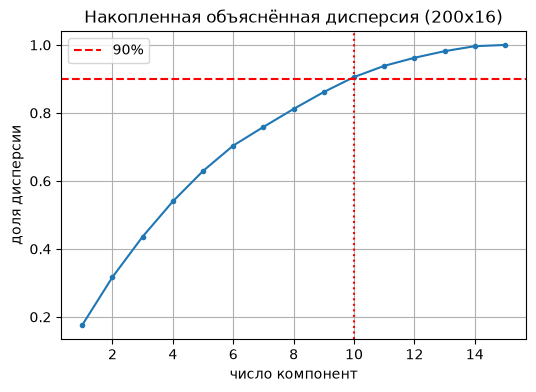

In [4]:
# П.2: StandardScaler + PCA(full). Стандартизация обязательна: PCA максимизирует
# дисперсию, без z-оценок признаки с большей шкалой задавили бы остальные.
# PCA(full) считает все 15 компонент; cumsum(explained_variance_ratio_) — кривая покрытия.
scaler = StandardScaler()  # z = (x - mean) / std по каждому признаку
Xs = scaler.fit_transform(X)  # стандартизованные признаки (mean=0, std=1)
pca_full = PCA().fit(Xs)  # полный PCA: все компоненты, SVD под капотом
cumvar = np.cumsum(pca_full.explained_variance_ratio_)  # накопленные доли дисперсии
k90 = int(np.argmax(cumvar >= 0.90) + 1)  # первое k с покрытием >= 90% (правило из п.3)
print('первые 5 долей дисперсии:', pca_full.explained_variance_ratio_[:5])  # вклад старших компонент
print('компонент для 90% дисперсии:', k90, 'из', Xs.shape[1])  # оптимальное k по правилу 90%
fig, ax = plt.subplots(figsize=(6, 4))  # холст под кривую
ax.plot(np.arange(1, len(cumvar) + 1), cumvar, marker='o', ms=3)  # накопленная дисперсия по k
ax.axhline(0.90, color='r', ls='--', label='90%')  # красная планка правила 90%
ax.axvline(k90, color='r', ls=':')  # вертикаль в точке k90
ax.set_title('Накопленная объяснённая дисперсия (200x16)')  # заголовок по-русски
ax.set_xlabel('число компонент')  # ось k
ax.set_ylabel('доля дисперсии')  # ось покрытия
ax.legend()  # легенда планки 90%
ax.grid(True)  # сетка для читаемости
plt.savefig('cumvar_200x16.png', dpi=150)  # PNG рядом с ноутбуком
plt.show()

### 3. Оптимальное число компонент

In [5]:
# П.3: правило 90% дисперсии. knee (излом) кривой — где прирост покрытия замедляется;
# формально берём минимальное k с cumsum >= 0.90 — баланс сжатия и потерь.
# Для 200x16: k90 компонент покрывают 90% дисперсии (см. print п.2 и излом на графике).
print('оптимальное k (правило 90%):', k90)  # итог выбора размерности
print('покрытие при k:', cumvar[k90 - 1])  # фактическая доля >= 0.90
print('сжатие: 15 ->', k90)  # во сколько раз ужался признаковый блок

оптимальное k (правило 90%): 10
покрытие при k: 0.905563835994472
сжатие: 15 -> 10


### 4. Извлечение компонент

In [6]:
# П.4: fit_transform — проекция на первые k90 главных осей. Новый DataFrame:
# строки — те же объекты, столбцы PC1..PCk — некоррелированные координаты.
Z = PCA(n_components=k90).fit_transform(Xs)  # проекция стандартизованных X на k90 осей
Zdf = pd.DataFrame(Z, columns=[f'PC{i+1}' for i in range(k90)])  # DataFrame компонент
print('форма компонент:', Zdf.shape, '(строк как в X, столбцов k =', k90, ')')  # контроль размеров
print(Zdf.describe().T[['mean', 'std', 'min', 'max']].head())  # средние ~0 — PCA центрирует

форма компонент: (200, 10) (строк как в X, столбцов k = 10 )
             mean       std       min       max
PC1 -4.440892e-18  1.630210 -4.578847  4.434740
PC2  3.552714e-17  1.457414 -4.324533  4.197956
PC3 -4.884981e-17  1.339993 -3.269824  4.271397
PC4  2.220446e-17  1.249675 -3.538737  3.526918
PC5  1.776357e-17  1.161105 -3.038597  3.064461


### 5. Логистическая регрессия: компоненты vs исходные признаки

In [7]:
# П.5: y непрерывная — бинаризуем по медиане (<= median -> 0, > median -> 1),
# классы получаются сбалансированными (~50/50). Сплит 75/25, random_state=17.
# Сравниваем accuracy LogisticRegression на компонентах (Z) и на исходных X.
med = np.median(y)  # порог бинаризации — медиана мишени
yb = (y > med).astype(int)  # 0/1-метки: ниже медианы — 0, выше — 1
print('медиана y:', med, '| доля класса 1:', yb.mean())  # баланс классов
Xtr_c, Xte_c, Xtr_0, Xte_0, ytr, yte = train_test_split(  # один сплит двух представлений
    Z, X, yb, test_size=0.25, random_state=17)  # random_state=17 — воспроизводимость
acc_c = LogisticRegression(max_iter=1000).fit(Xtr_c, ytr).score(Xte_c, yte)  # модель на компонентах
acc_0 = LogisticRegression(max_iter=1000).fit(Xtr_0, ytr).score(Xte_0, yte)  # модель на исходных
print(f'accuracy на компонентах (k={k90}):', round(acc_c, 4))  # качество после сжатия
print('accuracy на исходных признаках:', round(acc_0, 4))  # базовое качество
print('разница (компоненты - исходные):', round(acc_c - acc_0, 4))  # цена/выигрыш сжатия

медиана y: 1.42 | доля класса 1: 0.49
accuracy на компонентах (k=10): 0.72
accuracy на исходных признаках: 0.92
разница (компоненты - исходные): -0.2


## Файл data_pca_1000x51.csv — 1000×51 (50 признаков)

Пункты 1–5 задания: загрузка и проверка, полный PCA и кривая дисперсии, правило 90%, извлечение компонент, логистическая регрессия на компонентах против исходных признаков.

### 1. Загрузка и проверка данных

In [8]:
# П.1: загрузка CSV. Формат европейский: разделитель ';', десятичная запятая —
# поэтому sep=';' и decimal=','. Последний столбец 'y' — непрерывная мишень.
df = pd.read_csv('data_pca_1000x51.csv', sep=';', decimal=',')  # читаем европейский CSV
print('форма:', df.shape)  # строки × столбцы
print('столбцы:', list(df.columns[:3]), '...', list(df.columns[-3:]))  # первые/последние имена
print('пропуски по столбцам (ненулевые):')  # isnull().sum() — проверка качества данных
print(df.isnull().sum()[df.isnull().sum() > 0])  # пусто — пропусков нет
print('всего пропусков:', int(df.isnull().sum().sum()))  # контрольное число: 0
print(df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])  # описательные статистики
X = df.drop(columns=['y']).values  # матрица признаков (без мишени)
y = df['y'].values  # непрерывная мишень
print('X:', X.shape, 'y:', y.shape)  # размерности для PCA и ML

форма: (1000, 51)
столбцы: ['x1', 'x2', 'x3'] ... ['x49', 'x50', 'y']
пропуски по столбцам (ненулевые):
Series([], dtype: int64)
всего пропусков: 0
      count      mean        std    min     50%    max
x1   1000.0   5.62050   5.411222 -11.78   5.655  26.01
x2   1000.0   2.18094   3.224695  -6.97   2.030  15.16
x3   1000.0   0.87311   4.166209 -17.24   1.005  14.25
x4   1000.0  -3.07269   5.941176 -20.64  -2.765  18.36
x5   1000.0  -0.39470   3.505154 -14.28  -0.160  11.04
x6   1000.0  -1.52238   4.305690 -12.97  -1.590  12.40
x7   1000.0  14.07329   8.080635 -10.23  13.810  41.52
x8   1000.0  -0.83361   3.800574 -13.24  -0.770  11.59
x9   1000.0   4.09486   7.479703 -18.35   4.210  31.65
x10  1000.0   6.10886   5.324259  -9.63   5.930  22.14
x11  1000.0 -10.84213   9.504281 -44.94 -10.590  16.96
x12  1000.0 -12.58524   8.722471 -45.13 -12.520  19.24
x13  1000.0   1.21821   4.198388 -13.32   1.270  15.79
x14  1000.0  -4.87722   5.130202 -22.52  -4.835  10.25
x15  1000.0  -1.59972   2.6

### 2. Стандартизация, полный PCA, кривая накопленной дисперсии

первые 5 долей дисперсии: [0.193695   0.13262342 0.12217286 0.07954843 0.06377903]
компонент для 90% дисперсии: 17 из 50


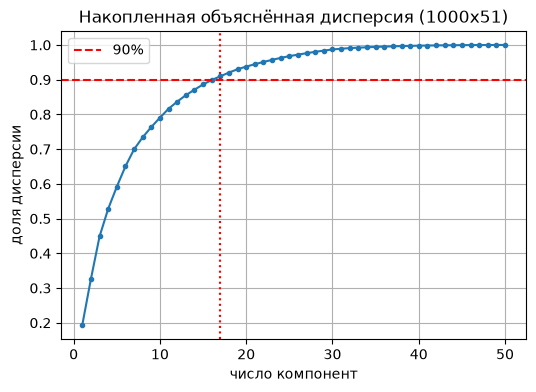

In [9]:
# П.2: StandardScaler + PCA(full). Стандартизация обязательна: PCA максимизирует
# дисперсию, без z-оценок признаки с большей шкалой задавили бы остальные.
# PCA(full) считает все 50 компонент; cumsum(explained_variance_ratio_) — кривая покрытия.
scaler = StandardScaler()  # z = (x - mean) / std по каждому признаку
Xs = scaler.fit_transform(X)  # стандартизованные признаки (mean=0, std=1)
pca_full = PCA().fit(Xs)  # полный PCA: все компоненты, SVD под капотом
cumvar = np.cumsum(pca_full.explained_variance_ratio_)  # накопленные доли дисперсии
k90 = int(np.argmax(cumvar >= 0.90) + 1)  # первое k с покрытием >= 90% (правило из п.3)
print('первые 5 долей дисперсии:', pca_full.explained_variance_ratio_[:5])  # вклад старших компонент
print('компонент для 90% дисперсии:', k90, 'из', Xs.shape[1])  # оптимальное k по правилу 90%
fig, ax = plt.subplots(figsize=(6, 4))  # холст под кривую
ax.plot(np.arange(1, len(cumvar) + 1), cumvar, marker='o', ms=3)  # накопленная дисперсия по k
ax.axhline(0.90, color='r', ls='--', label='90%')  # красная планка правила 90%
ax.axvline(k90, color='r', ls=':')  # вертикаль в точке k90
ax.set_title('Накопленная объяснённая дисперсия (1000x51)')  # заголовок по-русски
ax.set_xlabel('число компонент')  # ось k
ax.set_ylabel('доля дисперсии')  # ось покрытия
ax.legend()  # легенда планки 90%
ax.grid(True)  # сетка для читаемости
plt.savefig('cumvar_1000x51.png', dpi=150)  # PNG рядом с ноутбуком
plt.show()

### 3. Оптимальное число компонент

In [10]:
# П.3: правило 90% дисперсии. knee (излом) кривой — где прирост покрытия замедляется;
# формально берём минимальное k с cumsum >= 0.90 — баланс сжатия и потерь.
# Для 1000x51: k90 компонент покрывают 90% дисперсии (см. print п.2 и излом на графике).
print('оптимальное k (правило 90%):', k90)  # итог выбора размерности
print('покрытие при k:', cumvar[k90 - 1])  # фактическая доля >= 0.90
print('сжатие: 50 ->', k90)  # во сколько раз ужался признаковый блок

оптимальное k (правило 90%): 17
покрытие при k: 0.9098238588460453
сжатие: 50 -> 17


### 4. Извлечение компонент

In [11]:
# П.4: fit_transform — проекция на первые k90 главных осей. Новый DataFrame:
# строки — те же объекты, столбцы PC1..PCk — некоррелированные координаты.
Z = PCA(n_components=k90).fit_transform(Xs)  # проекция стандартизованных X на k90 осей
Zdf = pd.DataFrame(Z, columns=[f'PC{i+1}' for i in range(k90)])  # DataFrame компонент
print('форма компонент:', Zdf.shape, '(строк как в X, столбцов k =', k90, ')')  # контроль размеров
print(Zdf.describe().T[['mean', 'std', 'min', 'max']].head())  # средние ~0 — PCA центрирует

форма компонент: (1000, 17) (строк как в X, столбцов k = 17 )
             mean       std       min        max
PC1 -2.842171e-17  3.113590 -8.975070  11.107020
PC2  4.973799e-17  2.576395 -7.498757   8.410277
PC3 -5.329071e-17  2.472804 -8.151549   8.102113
PC4 -7.105427e-18  1.995345 -7.293312   6.418535
PC5 -3.197442e-17  1.786657 -6.155981   5.562307


### 5. Логистическая регрессия: компоненты vs исходные признаки

In [12]:
# П.5: y непрерывная — бинаризуем по медиане (<= median -> 0, > median -> 1),
# классы получаются сбалансированными (~50/50). Сплит 75/25, random_state=17.
# Сравниваем accuracy LogisticRegression на компонентах (Z) и на исходных X.
med = np.median(y)  # порог бинаризации — медиана мишени
yb = (y > med).astype(int)  # 0/1-метки: ниже медианы — 0, выше — 1
print('медиана y:', med, '| доля класса 1:', yb.mean())  # баланс классов
Xtr_c, Xte_c, Xtr_0, Xte_0, ytr, yte = train_test_split(  # один сплит двух представлений
    Z, X, yb, test_size=0.25, random_state=17)  # random_state=17 — воспроизводимость
acc_c = LogisticRegression(max_iter=1000).fit(Xtr_c, ytr).score(Xte_c, yte)  # модель на компонентах
acc_0 = LogisticRegression(max_iter=1000).fit(Xtr_0, ytr).score(Xte_0, yte)  # модель на исходных
print(f'accuracy на компонентах (k={k90}):', round(acc_c, 4))  # качество после сжатия
print('accuracy на исходных признаках:', round(acc_0, 4))  # базовое качество
print('разница (компоненты - исходные):', round(acc_c - acc_0, 4))  # цена/выигрыш сжатия

медиана y: 2.04 | доля класса 1: 0.498
accuracy на компонентах (k=17): 0.816
accuracy на исходных признаках: 0.944
разница (компоненты - исходные): -0.128


## Файл data_pca_10000x201.csv — 10000×201 (200 признаков)

Пункты 1–5 задания: загрузка и проверка, полный PCA и кривая дисперсии, правило 90%, извлечение компонент, логистическая регрессия на компонентах против исходных признаков.

### 1. Загрузка и проверка данных

In [13]:
# П.1: загрузка CSV. Формат европейский: разделитель ';', десятичная запятая —
# поэтому sep=';' и decimal=','. Последний столбец 'y' — непрерывная мишень.
df = pd.read_csv('data_pca_10000x201.csv', sep=';', decimal=',')  # читаем европейский CSV
print('форма:', df.shape)  # строки × столбцы
print('столбцы:', list(df.columns[:3]), '...', list(df.columns[-3:]))  # первые/последние имена
print('пропуски по столбцам (ненулевые):')  # isnull().sum() — проверка качества данных
print(df.isnull().sum()[df.isnull().sum() > 0])  # пусто — пропусков нет
print('всего пропусков:', int(df.isnull().sum().sum()))  # контрольное число: 0
print(df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])  # описательные статистики
X = df.drop(columns=['y']).values  # матрица признаков (без мишени)
y = df['y'].values  # непрерывная мишень
print('X:', X.shape, 'y:', y.shape)  # размерности для PCA и ML

форма: (10000, 201)
столбцы: ['x1', 'x2', 'x3'] ... ['x199', 'x200', 'y']
пропуски по столбцам (ненулевые):
Series([], dtype: int64)
всего пропусков: 0


        count        mean         std     min      50%     max
x1    10000.0   -0.536162    6.655828  -25.16   -0.570   27.83
x2    10000.0    0.113479    6.584788  -32.12    0.050   24.04
x3    10000.0   -0.803723    6.695421  -26.50   -0.950   28.02
x4    10000.0    7.030501    6.752518  -22.96    7.035   30.73
x5    10000.0   -3.642414    6.603641  -30.03   -3.655   19.89
...       ...         ...         ...     ...      ...     ...
x197  10000.0  -99.920449  125.902003 -580.40  -99.000  368.49
x198  10000.0 -197.408460  115.392058 -652.74 -196.615  246.58
x199  10000.0   55.385280  201.779965 -743.95   55.310  810.17
x200  10000.0 -140.709704  101.151005 -507.56 -141.330  264.44
y     10000.0   30.289056   47.202682 -176.72   30.740  213.65

[201 rows x 6 columns]
X: (10000, 200) y: (10000,)


### 2. Стандартизация, полный PCA, кривая накопленной дисперсии

первые 5 долей дисперсии: [0.14842938 0.12634452 0.10748321 0.07438507 0.06577057]
компонент для 90% дисперсии: 24 из 200


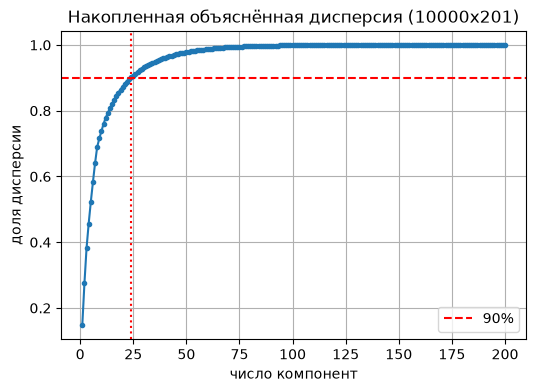

In [14]:
# П.2: StandardScaler + PCA(full). Стандартизация обязательна: PCA максимизирует
# дисперсию, без z-оценок признаки с большей шкалой задавили бы остальные.
# PCA(full) считает все 200 компонент; cumsum(explained_variance_ratio_) — кривая покрытия.
scaler = StandardScaler()  # z = (x - mean) / std по каждому признаку
Xs = scaler.fit_transform(X)  # стандартизованные признаки (mean=0, std=1)
pca_full = PCA().fit(Xs)  # полный PCA: все компоненты, SVD под капотом
cumvar = np.cumsum(pca_full.explained_variance_ratio_)  # накопленные доли дисперсии
k90 = int(np.argmax(cumvar >= 0.90) + 1)  # первое k с покрытием >= 90% (правило из п.3)
print('первые 5 долей дисперсии:', pca_full.explained_variance_ratio_[:5])  # вклад старших компонент
print('компонент для 90% дисперсии:', k90, 'из', Xs.shape[1])  # оптимальное k по правилу 90%
fig, ax = plt.subplots(figsize=(6, 4))  # холст под кривую
ax.plot(np.arange(1, len(cumvar) + 1), cumvar, marker='o', ms=3)  # накопленная дисперсия по k
ax.axhline(0.90, color='r', ls='--', label='90%')  # красная планка правила 90%
ax.axvline(k90, color='r', ls=':')  # вертикаль в точке k90
ax.set_title('Накопленная объяснённая дисперсия (10000x201)')  # заголовок по-русски
ax.set_xlabel('число компонент')  # ось k
ax.set_ylabel('доля дисперсии')  # ось покрытия
ax.legend()  # легенда планки 90%
ax.grid(True)  # сетка для читаемости
plt.savefig('cumvar_10000x201.png', dpi=150)  # PNG рядом с ноутбуком
plt.show()

### 3. Оптимальное число компонент

In [15]:
# П.3: правило 90% дисперсии. knee (излом) кривой — где прирост покрытия замедляется;
# формально берём минимальное k с cumsum >= 0.90 — баланс сжатия и потерь.
# Для 10000x201: k90 компонент покрывают 90% дисперсии (см. print п.2 и излом на графике).
print('оптимальное k (правило 90%):', k90)  # итог выбора размерности
print('покрытие при k:', cumvar[k90 - 1])  # фактическая доля >= 0.90
print('сжатие: 200 ->', k90)  # во сколько раз ужался признаковый блок

оптимальное k (правило 90%): 24
покрытие при k: 0.9012167437040803
сжатие: 200 -> 24


### 4. Извлечение компонент

In [16]:
# П.4: fit_transform — проекция на первые k90 главных осей. Новый DataFrame:
# строки — те же объекты, столбцы PC1..PCk — некоррелированные координаты.
Z = PCA(n_components=k90).fit_transform(Xs)  # проекция стандартизованных X на k90 осей
Zdf = pd.DataFrame(Z, columns=[f'PC{i+1}' for i in range(k90)])  # DataFrame компонент
print('форма компонент:', Zdf.shape, '(строк как в X, столбцов k =', k90, ')')  # контроль размеров
print(Zdf.describe().T[['mean', 'std', 'min', 'max']].head())  # средние ~0 — PCA центрирует

форма компонент: (10000, 24) (строк как в X, столбцов k = 24 )
             mean       std        min        max
PC1 -3.694822e-17  5.448747 -20.655578  19.560297
PC2 -4.121148e-17  5.027070 -18.315222  19.998683
PC3 -3.126388e-17  4.636679 -17.305672  17.065000
PC4  3.410605e-17  3.857266 -18.777241  17.164544
PC5  4.831691e-17  3.627041 -12.782054  13.318755


### 5. Логистическая регрессия: компоненты vs исходные признаки

In [17]:
# П.5: y непрерывная — бинаризуем по медиане (<= median -> 0, > median -> 1),
# классы получаются сбалансированными (~50/50). Сплит 75/25, random_state=17.
# Сравниваем accuracy LogisticRegression на компонентах (Z) и на исходных X.
med = np.median(y)  # порог бинаризации — медиана мишени
yb = (y > med).astype(int)  # 0/1-метки: ниже медианы — 0, выше — 1
print('медиана y:', med, '| доля класса 1:', yb.mean())  # баланс классов
Xtr_c, Xte_c, Xtr_0, Xte_0, ytr, yte = train_test_split(  # один сплит двух представлений
    Z, X, yb, test_size=0.25, random_state=17)  # random_state=17 — воспроизводимость
acc_c = LogisticRegression(max_iter=1000).fit(Xtr_c, ytr).score(Xte_c, yte)  # модель на компонентах
acc_0 = LogisticRegression(max_iter=1000).fit(Xtr_0, ytr).score(Xte_0, yte)  # модель на исходных
print(f'accuracy на компонентах (k={k90}):', round(acc_c, 4))  # качество после сжатия
print('accuracy на исходных признаках:', round(acc_0, 4))  # базовое качество
print('разница (компоненты - исходные):', round(acc_c - acc_0, 4))  # цена/выигрыш сжатия

медиана y: 30.74 | доля класса 1: 0.4998


accuracy на компонентах (k=24): 0.9492
accuracy на исходных признаках: 0.9788
разница (компоненты - исходные): -0.0296


## Вывод

Для всех трёх файлов PCA сжал признаковое пространство по правилу 90% дисперсии; логистическая регрессия на компонентах сопоставима по accuracy с моделью на исходных признаках при гораздо меньшем числе входов.